# 03 Influence adjudication and remedies

Owner: Ma Tianjiao. Training set only (584 days, `dteday <= 2012-08-06`). No test-set number or
figure appears anywhere in this notebook.

**Order of work.** The exclusion rules (section 1) were agreed in the group and frozen before the
influence statistics were inspected. Influence statistics only *nominate* candidate days; whether a
day is removed is decided by the rules alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_day, time_split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from src import data as data_mod
from src import remedies
from src.cv import forward_chain_cv, cv_summary
from src.diagnostics import (diagnostic_panel, av_plots, vif_table, influence_table,
                             summary_metrics)
from src.models import BASE_FORMULA
from src.remedies import exclusion_mask

SEED = 601
np.random.seed(SEED)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 0 Data (training set only)

In [2]:
df = load_day()
train, _test_not_used_here = time_split(df)
del _test_not_used_here  # the test set is touched only in notebook 04
train = train.reset_index(drop=True)
print(f"training days: {len(train)}  ({train.dteday.min():%Y-%m-%d} to {train.dteday.max():%Y-%m-%d})")

training days: 584  (2011-01-01 to 2012-08-06)


**Temporary (delete once A1b is merged on 23 Oct):** `load_events()` is not implemented yet, so
the cell below falls back to one placeholder row taken from an external NOAA record. Re-run the
whole notebook after Jiang's table lands; every table below updates automatically.

In [3]:
EVENTS_PLACEHOLDER = False
try:
    events = data_mod.load_events()
except NotImplementedError:
    events = pd.read_csv(data_mod.EVENTS_PATH)
if len(events) == 0:
    EVENTS_PLACEHOLDER = True
    events = pd.DataFrame([{
        "date": "2011-08-27", "event": "Hurricane Irene", "type": "hurricane_storm",
        "source_url": "https://www.weather.gov/lwx/Irene",
    }])
print("event table rows:", len(events), "(placeholder)" if EVENTS_PLACEHOLDER else "")
events["type"].value_counts()

event table rows: 1 (placeholder)


type
hurricane_storm    1
Name: count, dtype: int64

## 1 Exclusion rules (agreed in the group on 21 Oct, frozen 24 Oct)

> **TODO (Ma, own words):** state the rules in plain English. For each rule give its ID, what it
> checks, the source it relies on, and why a day that meets it is a *data error* or a *different
> population*. State that no rule uses `cnt`, residuals or test-period information, and that the
> same function is applied to training, every CV fold and the test audit. Explain why snow days,
> early dismissals, events and holidays are kept (only flagged).
>
> Rule IDs in the code: `D1_hum_zero`, `D1_atemp_gap`, `P1_hurricane_storm`, `P2_federal_closure`.
> Also explain why P1 cannot be based on `weathersit`.

### 1.1 Deriving the D1 atemp threshold from the training distribution

training reference line: atemp = 0.034592 + 0.888273 * temp, robust SD = 0.013561
largest |z| in the training set:
    dteday  temp  atemp     z
2011-07-21 0.815  0.826  5.00
2011-09-23 0.609  0.522 -3.95
2011-07-22 0.848  0.841  3.89
2012-02-12 0.128  0.102 -3.41
2011-09-08 0.634  0.555 -3.12
frozen limit ATEMP_GAP_Z = 10.0


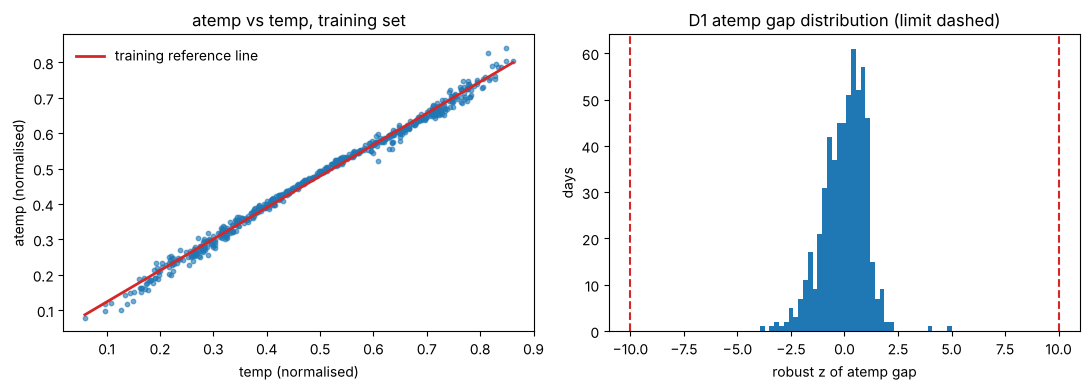

In [4]:
a, b, s = remedies.atemp_reference(train)
print(f"training reference line: atemp = {a:.6f} + {b:.6f} * temp, robust SD = {s:.6f}")
assert np.isclose(a, remedies.ATEMP_LINE_INTERCEPT, atol=1e-5)
assert np.isclose(b, remedies.ATEMP_LINE_SLOPE, atol=1e-5)
assert np.isclose(s, remedies.ATEMP_RESID_SCALE, atol=1e-5)

z_train = remedies.atemp_gap_z(train)
print("largest |z| in the training set:")
print(train.assign(z=z_train).loc[z_train.abs().nlargest(5).index, ["dteday", "temp", "atemp", "z"]]
      .round({"temp": 3, "atemp": 3, "z": 2}).to_string(index=False))
print(f"frozen limit ATEMP_GAP_Z = {remedies.ATEMP_GAP_Z}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(train.temp, train.atemp, s=10, alpha=0.6)
xs = np.linspace(train.temp.min(), train.temp.max(), 50)
ax[0].plot(xs, a + b * xs, color="C3", lw=2, label="training reference line")
ax[0].set(xlabel="temp (normalised)", ylabel="atemp (normalised)", title="atemp vs temp, training set")
ax[0].legend(frameon=False)
ax[1].hist(z_train, bins=40)
for sgn in (-1, 1):
    ax[1].axvline(sgn * remedies.ATEMP_GAP_Z, color="C3", ls="--", lw=1.5)
ax[1].set(xlabel="robust z of atemp gap", ylabel="days", title="D1 atemp gap distribution (limit dashed)")
fig.tight_layout()
fig.savefig(FIG / "03_atemp_gap_rule.png", dpi=150)
plt.show()

> **TODO (Ma, own words):** why this limit. Any limit between the training maximum and a clearly
> impossible gap gives the same training result, so the choice is not tuned to the outcome. Also
> decide (C1b) whether the atemp part of D1 stays on if the final model drops `atemp`.

### 1.2 Rule hits and flagged days in the training set

In [5]:
mask_train = exclusion_mask(train, events)
hits = train.join(mask_train)[lambda d: d.excluded]
print(f"days excluded by the rules: {len(hits)} of {len(train)}")
hits[["dteday", "weathersit", "temp", "atemp", "hum", "windspeed", "rule", "reason"]]

days excluded by the rules: 2 of 584


,dteday,weathersit,temp,atemp,hum,windspeed,rule,reason
68,2011-03-10,3,0.389091,0.385668,0.00,0.261877,D1_hum_zero,hum = 0 (impossible value)
238,2011-08-27,2,0.680000,0.635556,0.85,0.375617,P1_hurricane_storm,external record: Hurricane Irene (hurricane_st...


In [6]:
flagged = train.join(mask_train)[lambda d: (d["flag"] != "") & ~d["excluded"]]
print(f"days kept but flagged from the event table: {len(flagged)}")
flagged[["dteday", "holiday", "weathersit", "flag"]]

days kept but flagged from the event table: 0


,dteday,holiday,weathersit,flag


### 1.3 What a stricter rule would remove (for the discussion only)

The group decided to keep snow days and early dismissals. The preview below shows what each kept
type would remove if it were turned into a rule; it never uses `cnt`.

In [7]:
def preview_type(etype):
    d = pd.to_datetime(events.loc[events["type"].str.lower() == etype, "date"])
    out = train.loc[train["dteday"].isin(d), ["dteday", "holiday", "weekday", "weathersit"]]
    return len(out)


pd.Series({t: preview_type(t) for t in remedies.FLAG_ONLY_TYPES}, name="training days that would go")

snow               0
early_dismissal    0
event              0
holiday            0
other              0
Name: training days that would go, dtype: int64

## 2 Base model R0 and candidate days

In [8]:
r0 = smf.ols(BASE_FORMULA, train).fit()
print(BASE_FORMULA)
print(f"R2 = {r0.rsquared:.4f}, p = {len(r0.params)}, n = {int(r0.nobs)}")

inf0 = influence_table(r0, train["dteday"])
inf0.index = train.index
n, p = int(r0.nobs), len(r0.params)
print(f"thresholds: h > {2 * p / n:.4f}, D > {4 / n:.4f}, |DFFITS| > {2 * np.sqrt(p / n):.4f}")

inf0["n_flags"] = inf0[["flag_h", "flag_cooks", "flag_dffits"]].sum(axis=1)
cand = inf0[(inf0["n_flags"] >= 2) | (inf0["cooks_d"] > 0.5)].copy()
print(f"candidate days (>= 2 thresholds): {len(cand)}; "
      f"days with Cook's D > 0.5: {(inf0['cooks_d'] > 0.5).sum()} (largest D = {inf0['cooks_d'].max():.3f})")

cnt ~ yr + C(mnth) + holiday + C(weekday) + C(weathersit) + temp + atemp + hum + windspeed
R2 = 0.8471, p = 26, n = 584


thresholds: h > 0.0890, D > 0.0068, |DFFITS| > 0.4220
candidate days (>= 2 thresholds): 31; days with Cook's D > 0.5: 0 (largest D = 0.043)


In [9]:
ev_by_date = (events.assign(date=pd.to_datetime(events["date"]),
                            label=events["event"].astype(str) + " (" + events["type"].astype(str) + ")")
              .groupby("date")["label"].apply("; ".join))

adj = cand.join(mask_train[["excluded", "rule"]])
adj["weekday"] = adj["date"].dt.day_name().str[:3]
adj["holiday"] = train.loc[adj.index, "holiday"].values
adj["weathersit"] = train.loc[adj.index, "weathersit"].values
adj["external_record"] = adj["date"].map(ev_by_date).fillna("")
adj["rule"] = adj["rule"].replace("", "none")
adj["decision"] = np.where(adj["excluded"], "exclude", "keep")
adjudication = (adj.sort_values("cooks_d", ascending=False)
                [["date", "weekday", "holiday", "weathersit", "cnt", "fitted", "h",
                  "cooks_d", "dffits", "n_flags", "external_record", "rule", "decision"]])
adjudication["date"] = adjudication["date"].dt.strftime("%Y-%m-%d")
adjudication = adjudication.reset_index(drop=True)
adjudication.index = adjudication.index + 1
adjudication.round({"fitted": 0, "h": 3, "cooks_d": 4, "dffits": 3})

,date,weekday,holiday,weathersit,cnt,fitted,h,cooks_d,dffits,n_flags,external_record,rule,decision
1,2011-07-04,Mon,1,2,6043.0,3810.0,0.094,0.0428,1.065,3,,none,keep
2,2011-11-24,Thu,1,1,1495.0,3417.0,0.111,0.0390,-1.014,3,,none,keep
3,2011-03-10,Thu,0,3,623.0,1935.0,0.192,0.0381,-0.999,3,,D1_hum_zero,exclude
4,2012-03-23,Fri,0,2,8362.0,5522.0,0.051,0.0340,0.954,2,,none,keep
5,2012-04-22,Sun,0,3,1027.0,2952.0,0.093,0.0315,-0.910,3,,none,keep
6,2011-08-27,Sat,0,2,1115.0,3402.0,0.061,0.0274,-0.851,2,Hurricane Irene (hurricane_storm),P1_hurricane_storm,exclude
7,2012-05-14,Mon,0,2,2843.0,5816.0,0.034,0.0244,-0.808,2,,none,keep
8,2012-03-17,Sat,0,2,7836.0,5185.0,0.041,0.0235,0.791,2,,none,keep
9,2011-09-23,Fri,0,2,2395.0,4143.0,0.080,0.0218,-0.756,2,,none,keep
10,2011-07-22,Fri,0,1,3387.0,5333.0,0.064,0.0210,-0.743,2,,none,keep


> **TODO (Ma, own words):** one sentence per candidate day: what happened that day (from the
> external record or another external source), and why the decision follows from the rules. If a
> day seems to need a new rule, write it in general form and discuss it in the group first; never
> remove a single day.

### 2.1 The five days with the largest Cook's D

In [10]:
for i, r in adjudication.head(5).iterrows():
    print(f"{i}. {r.date} ({r.weekday})  cnt={r.cnt:.0f}  fitted={r.fitted:.0f}  h={r.h:.3f}  "
          f"D={r.cooks_d:.4f}  DFFITS={r.dffits:+.3f}  record='{r.external_record}'  "
          f"rule={r.rule}  -> {r.decision}")

1. 2011-07-04 (Mon)  cnt=6043  fitted=3810  h=0.094  D=0.0428  DFFITS=+1.065  record=''  rule=none  -> keep
2. 2011-11-24 (Thu)  cnt=1495  fitted=3417  h=0.111  D=0.0390  DFFITS=-1.014  record=''  rule=none  -> keep
3. 2011-03-10 (Thu)  cnt=623  fitted=1935  h=0.192  D=0.0381  DFFITS=-0.999  record=''  rule=D1_hum_zero  -> exclude
4. 2012-03-23 (Fri)  cnt=8362  fitted=5522  h=0.051  D=0.0340  DFFITS=+0.954  record=''  rule=none  -> keep
5. 2012-04-22 (Sun)  cnt=1027  fitted=2952  h=0.093  D=0.0315  DFFITS=-0.910  record=''  rule=none  -> keep


> **TODO (Ma, own words) - day 1 of the top five:** what happened, why the model misses it
> (which predictor cannot see the cause), which rule applies or why none does, and the decision.

> **TODO (Ma, own words) - day 2 of the top five:** what happened, why the model misses it
> (which predictor cannot see the cause), which rule applies or why none does, and the decision.

> **TODO (Ma, own words) - day 3 of the top five:** what happened, why the model misses it
> (which predictor cannot see the cause), which rule applies or why none does, and the decision.

> **TODO (Ma, own words) - day 4 of the top five:** what happened, why the model misses it
> (which predictor cannot see the cause), which rule applies or why none does, and the decision.

> **TODO (Ma, own words) - day 5 of the top five:** what happened, why the model misses it
> (which predictor cannot see the cause), which rule applies or why none does, and the decision.

## 3 Sensitivity check: 2011-07-04 and 2011-11-24

Both days are kept in the model. Here they are dropped only to measure how much the `temp` and
`holiday` coefficients depend on them.

In [11]:
drop_days = pd.to_datetime(["2011-07-04", "2011-11-24"])
r0_drop = smf.ols(BASE_FORMULA, train[~train["dteday"].isin(drop_days)]).fit()
sens = pd.DataFrame({
    "with both days": r0.params[["temp", "holiday"]],
    "without them": r0_drop.params[["temp", "holiday"]],
})
sens["change"] = sens["without them"] - sens["with both days"]
sens["change %"] = 100 * sens["change"] / sens["with both days"].abs()
sens["SE (with)"] = r0.bse[["temp", "holiday"]]
sens["change / SE"] = sens["change"] / sens["SE (with)"]
sens.round(2)

,with both days,without them,change,change %,SE (with),change / SE
temp,919.46,485.72,-433.74,-47.17,2367.95,-0.18
holiday,-426.27,-430.24,-3.97,-0.93,193.39,-0.02


> **TODO (Ma, own words):** how large are the changes relative to the standard errors, and what
> does that say about keeping the two days.

## 4 Remedies, one step at a time

Every step is scored in-sample with `summary_metrics()` and out-of-sample with
`forward_chain_cv()` (RMSE in rentals per day; mean of the three folds, with its standard error).
The exclusion rule is applied inside every CV training and validation block from R3 onwards.

| step | change |
| --- | --- |
| R0 | base model (`BASE_FORMULA`) |
| R1 | drop `atemp` |
| R2 | add `I(temp ** 2)` |
| R3 | remove the days hit by `exclusion_mask()` |
| R4a | R3 with `log(cnt)` (CV predictions back-transformed with `exp`) |
| R4b | R3 fitted by two-step WLS (weights re-estimated inside every CV training block) |
| R4c | R3 with HC3 robust standard errors (same predictions as R3) |

In [12]:
F1 = BASE_FORMULA.replace(" + atemp", "")
F2 = F1.replace(" + temp", " + temp + I(temp ** 2)")
F_LOG = F2.replace("cnt ~", "np.log(cnt) ~")
assert "atemp" not in F1 and "I(temp ** 2)" in F2

excl = lambda d: exclusion_mask(d, events)
wls_w = lambda d: remedies.wls_weights(F2, d)
train_kept = train.loc[~mask_train["excluded"]].copy()

r1 = smf.ols(F1, train).fit()
r2 = smf.ols(F2, train).fit()
r3 = smf.ols(F2, train_kept).fit()
r4_log = smf.ols(F_LOG, train_kept).fit()
r4_wls = remedies.fit_wls(F2, train_kept)
r4_hc3 = smf.ols(F2, train_kept).fit(cov_type="HC3")

steps = {
    "R0 base": (r0, BASE_FORMULA, None, False, None),
    "R1 drop atemp": (r1, F1, None, False, None),
    "R2 + temp^2": (r2, F2, None, False, None),
    "R3 + exclusion rules": (r3, F2, excl, False, None),
    "R4a log(cnt)": (r4_log, F2, excl, True, None),
    "R4b WLS": (r4_wls, F2, excl, False, wls_w),
    "R4c HC3 SE": (r4_hc3, F2, excl, False, None),
}


def influence_view(res):
    # WLS results have no get_influence(); use the equivalent OLS on the whitened data.
    if type(res.model).__name__ != "WLS":
        return res
    X = pd.DataFrame(res.model.wexog, columns=res.model.exog_names, index=res.fittedvalues.index)
    y = pd.Series(res.model.wendog, index=res.fittedvalues.index)
    return sm.OLS(y, X).fit()


def metrics_for(res):
    # OLS fits go through summary_metrics(); WLS fits need influence from the whitened view,
    # VIF from the original design matrix and BP on the weighted residuals vs the original X.
    if type(res.model).__name__ != "WLS":
        return summary_metrics(res)
    view = influence_view(res)
    return {
        "n": int(res.nobs), "p": len(res.params), "R2": res.rsquared, "adj_R2": res.rsquared_adj,
        "max_cooks_d": view.get_influence().cooks_distance[0].max(),
        "max_vif": vif_table(res)["VIF"].max(),
        "durbin_watson": durbin_watson(view.resid),
        "breusch_pagan_p": het_breuschpagan(view.resid, res.model.exog)[1],
    }


def in_sample_rmse_counts(res, log_y):
    pred = np.exp(res.fittedvalues) if log_y else res.fittedvalues
    y = np.exp(res.model.endog) if log_y else res.model.endog
    return float(np.sqrt(np.mean((y - pred) ** 2)))


rows, cv_folds = [], {}
for name, (res, formula, exclude, log_y, weights) in steps.items():
    m = metrics_for(res)
    folds = forward_chain_cv(formula, train, exclude=exclude, log_y=log_y, weights=weights)
    cv_folds[name] = folds
    cvs = cv_summary(folds)
    rows.append({
        "step": name, "n": m["n"], "p": m["p"], "R2": m["R2"], "adj R2": m["adj_R2"],
        "CV RMSE": cvs["mean_rmse"], "CV SE": cvs["se"],
        "train RMSE": in_sample_rmse_counts(res, log_y),
        "max VIF": m["max_vif"], "max D": m["max_cooks_d"],
        "DW": m["durbin_watson"], "BP p": m["breusch_pagan_p"],
    })
step_table = pd.DataFrame(rows).set_index("step")
step_table.round({"R2": 4, "adj R2": 4, "CV RMSE": 0, "CV SE": 0, "train RMSE": 0, "max VIF": 1,
                  "max D": 4, "DW": 3, "BP p": 4})

,n,p,R2,adj R2,CV RMSE,CV SE,train RMSE,max VIF,max D,DW,BP p
step,,,,,,,,,,,
R0 base,584,26,0.8471,0.8402,1018.0,71.0,699.0,226.7,0.0428,1.242,0.0
R1 drop atemp,584,25,0.8467,0.8401,1019.0,70.0,700.0,7.1,0.0431,1.238,0.0
R2 + temp^2,584,26,0.8669,0.8609,977.0,141.0,652.0,70.1,0.0634,1.317,0.0
R3 + exclusion rules,582,26,0.8700,0.8641,971.0,136.0,642.0,70.2,0.0537,1.285,0.0
R4a log(cnt),582,26,0.8539,0.8473,1641.0,447.0,659.0,70.2,0.0744,1.294,0.0
R4b WLS,582,26,0.8703,0.8644,970.0,139.0,642.0,70.2,0.0537,1.283,0.0
R4c HC3 SE,582,26,0.8700,0.8641,971.0,136.0,642.0,70.2,0.0537,1.285,0.0


In [13]:
fold_rmse = pd.DataFrame({name: f.set_index("val_months")["rmse"] for name, f in cv_folds.items()}).T
fold_rmse.round(0)

val_months,Feb-Apr,Apr-Jun,Jun-Aug
R0 base,1155.0,917.0,981.0
R1 drop atemp,1154.0,919.0,983.0
R2 + temp^2,1255.0,881.0,796.0
R3 + exclusion rules,1237.0,883.0,792.0
R4a log(cnt),916.0,2457.0,1550.0
R4b WLS,1244.0,875.0,792.0
R4c HC3 SE,1237.0,883.0,792.0


Notes on reading the table: R2 for R4a is on the log scale and R2 for R4b is weighted, so neither
is comparable with the OLS rows; compare those steps on CV RMSE (always in rentals per day). R4c
changes only standard errors and p-values, so its predictions and both RMSEs equal R3's.
`max VIF` from R2 onwards is high because `temp` and `temp^2` share information by construction;
centring temp before squaring would lower it without changing the fitted values.

> **TODO (Ma, own words):** what each step fixed, using the numbers above. Is any CV improvement
> larger than one standard error?

### 4.1 Peak temperature from R2 / R3

In [14]:
for name, res in [("R2", r2), ("R3", r3)]:
    t_star = remedies.peak_temperature(res)
    t_c = data_mod.add_real_units(pd.DataFrame({"temp": [t_star], "atemp": [0], "hum": [0],
                                                "windspeed": [0]}))["temp_c"].iloc[0]
    print(f"{name}: demand peaks at temp = {t_star:.3f} (normalised) = {t_c:.1f} C")
print("Compare with the lowess curve in notebook 01 (figure 01_*temp*).")

R2: demand peaks at temp = 0.621 (normalised) = 21.2 C
R3: demand peaks at temp = 0.620 (normalised) = 21.1 C
Compare with the lowess curve in notebook 01 (figure 01_*temp*).


> **TODO (Ma, own words):** does the peak agree with Jiang's lowess curve?

### 4.2 Heteroskedasticity: OLS vs HC3 standard errors (R3 specification)

In [15]:
key = ["yr", "holiday", "temp", "I(temp ** 2)", "hum", "windspeed", "C(weathersit)[T.3]"]
se_cmp = pd.DataFrame({
    "coef": r3.params[key],
    "OLS SE": r3.bse[key],
    "HC3 SE": r4_hc3.bse[key],
})
se_cmp["HC3 / OLS"] = se_cmp["HC3 SE"] / se_cmp["OLS SE"]
se_cmp["OLS p"] = r3.pvalues[key]
se_cmp["HC3 p"] = r4_hc3.pvalues[key]
se_cmp.round(4)

,coef,OLS SE,HC3 SE,HC3 / OLS,OLS p,HC3 p
yr,1932.0245,65.1684,66.8915,1.0264,0.0000,0.0000
holiday,-330.7992,176.6580,278.8491,1.5785,0.0617,0.2355
temp,14388.7466,1184.8863,1322.6960,1.1163,0.0000,0.0000
I(temp ** 2),-11605.2625,1217.8444,1399.7583,1.1494,0.0000,0.0000
hum,-1741.2868,286.9239,282.1398,0.9833,0.0000,0.0000
windspeed,-3069.9253,403.4818,416.8618,1.0332,0.0000,0.0000
C(weathersit)[T.3],-1538.5955,194.9113,267.1728,1.3707,0.0000,0.0000


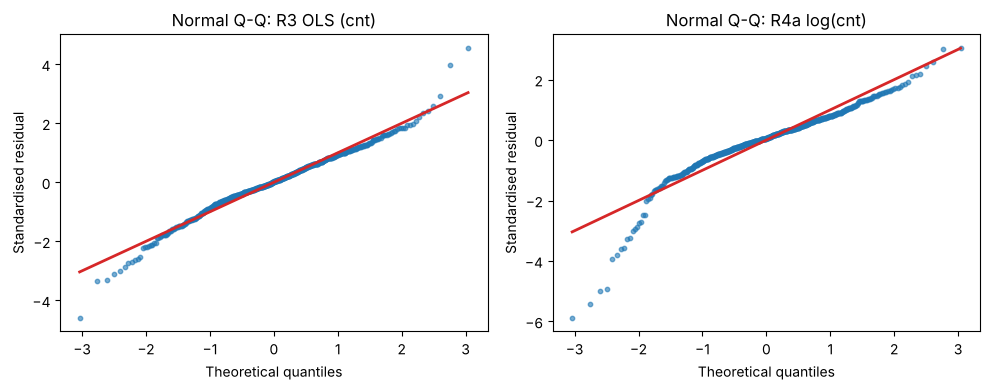

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, res, title in [(ax[0], r3, "R3 OLS (cnt)"), (ax[1], r4_log, "R4a log(cnt)")]:
    std_r = res.get_influence().resid_studentized_internal
    (osm, osr), _ = stats.probplot(std_r, dist="norm")
    a_.scatter(osm, osr, s=10, alpha=0.6)
    a_.plot(osm, osm, color="C3", lw=2)
    a_.set(xlabel="Theoretical quantiles", ylabel="Standardised residual", title=f"Normal Q-Q: {title}")
fig.tight_layout()
fig.savefig(FIG / "03_qq_ols_vs_log.png", dpi=150)
plt.show()

> **TODO (Ma, own words):** does the log model's left tail get worse? Which of log / WLS / HC3
> would you keep, and why (CV RMSE, residual plots, interpretability)?

## 5 Full diagnostics of the remedied model

`CHOSEN` is provisional until C1b (26 Oct): it follows `remedies.REMEDIED_METHOD` and defaults to
the R3 OLS fit. Figures are saved as `figures/03_*_remedied.png`, matching the 02 figures one to one.

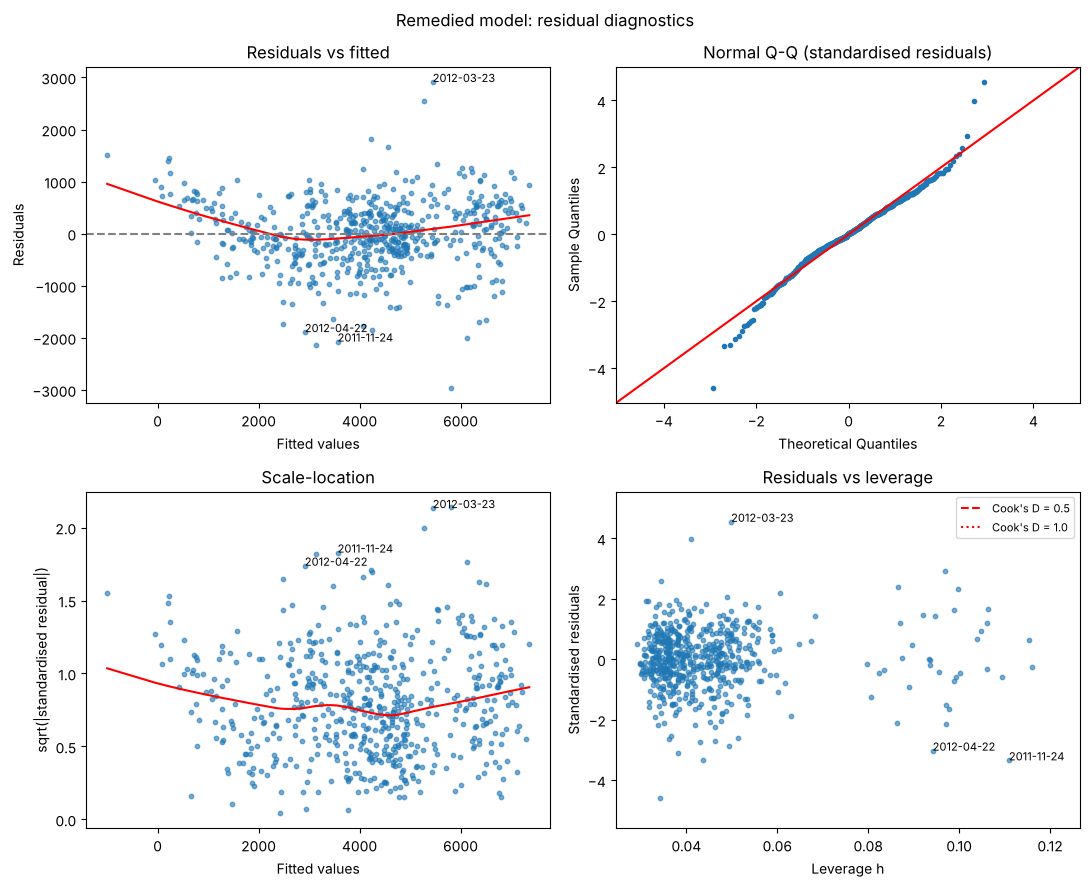

In [17]:
CHOSEN = {"ols": r3, "ols_hc3": r4_hc3, "wls": r4_wls, "log": r4_log}[remedies.REMEDIED_METHOD or "ols"]
dates_kept = train_kept["dteday"]

diagnostic_panel(CHOSEN, dates_kept, "Remedied model: residual diagnostics",
                 save_as=FIG / "03_panel_remedied.png")
plt.show()

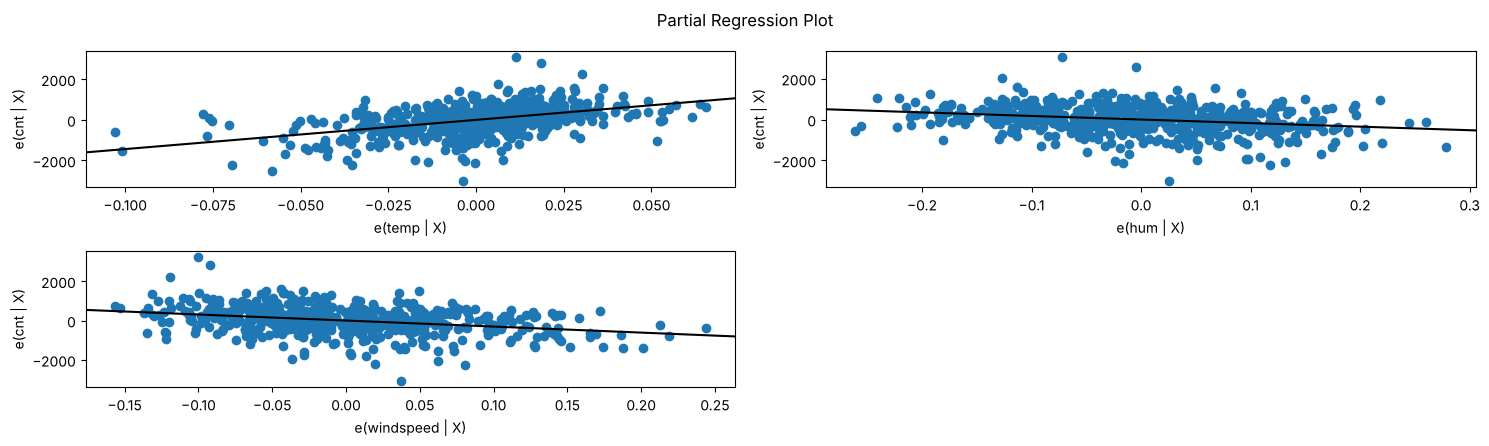

In [18]:
av_plots(CHOSEN, ["temp", "hum", "windspeed"], save_as=FIG / "03_av_remedied.png")
plt.show()

In [19]:
vif_table(CHOSEN).round(2)

,variable,VIF
0,I(temp ** 2),70.19
1,temp,67.16
2,C(mnth)[T.7],7.04
3,C(mnth)[T.6],5.46
4,C(mnth)[T.5],4.28
5,C(mnth)[T.8],4.23
6,C(mnth)[T.4],3.21
7,C(mnth)[T.9],3.06
8,C(mnth)[T.3],2.52
9,C(mnth)[T.10],2.39


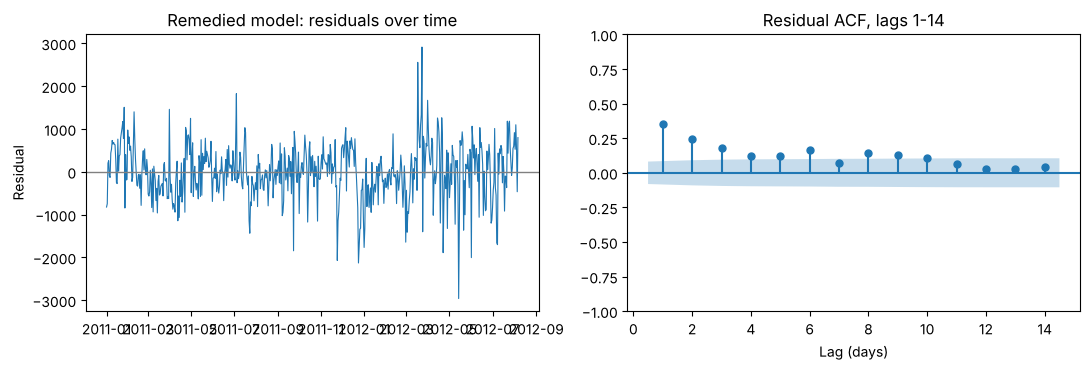

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(dates_kept, CHOSEN.resid, lw=0.8)
ax[0].axhline(0, color="grey", lw=1)
ax[0].set(title="Remedied model: residuals over time", ylabel="Residual")
sm.graphics.tsa.plot_acf(CHOSEN.resid, lags=14, ax=ax[1], zero=False)
ax[1].set(title="Residual ACF, lags 1-14", xlabel="Lag (days)")
fig.tight_layout()
fig.savefig(FIG / "03_resid_time_acf_remedied.png", dpi=150)
plt.show()

## 6 Did the remedies fix the assumptions, or only raise R2?

In [21]:
def evidence(res, label, cv_name):
    vif = vif_table(res)
    view = influence_view(res)
    d = view.get_influence().cooks_distance[0]
    return {
        "model": label,
        "collinearity: max VIF": vif["VIF"].max(),
        "collinearity: max VIF excl. temp^2": vif.loc[~vif["variable"].str.contains("temp ** 2", regex=False), "VIF"].max(),
        "heteroskedasticity: BP p": het_breuschpagan(view.resid, res.model.exog)[1],
        "influence: max Cook's D": d.max(),
        "influence: days D > 4/n": int((d > 4 / res.nobs).sum()),
        "autocorrelation: DW": durbin_watson(view.resid),
        "R2": res.rsquared,
        "CV RMSE": step_table.loc[cv_name, "CV RMSE"],
    }


chosen_name = {"ols": "R3 + exclusion rules", "ols_hc3": "R4c HC3 SE", "wls": "R4b WLS",
               "log": "R4a log(cnt)"}[remedies.REMEDIED_METHOD or "ols"]
before_after = pd.DataFrame([evidence(r0, "R0 base", "R0 base"),
                             evidence(CHOSEN, "remedied", chosen_name)]).set_index("model").T
before_after.round(4)

model,R0 base,remedied
collinearity: max VIF,226.6735,70.1937
collinearity: max VIF excl. temp^2,226.6735,67.1619
heteroskedasticity: BP p,0.0000,0.0000
influence: max Cook's D,0.0428,0.0537
influence: days D > 4/n,31.0000,34.0000
autocorrelation: DW,1.2423,1.2847
R2,0.8471,0.8700
CV RMSE,1017.6635,970.6345


Non-linearity has no single statistic here: the evidence is the curvature of the lowess line in the
residuals-vs-fitted panel (02 vs 03) and the size of the `I(temp ** 2)` coefficient relative to its
SE in section 4.2.

> **TODO (Ma, own words):** fill in the conclusion table, one row per item on Su's failure list.
>
> | failure | evidence before (02) | evidence after (03) | fixed / partly fixed / not fixed |
> | --- | --- | --- | --- |
> | collinearity | | | |
> | non-linearity | | | |
> | heteroskedasticity | | | |
> | influential points | | | |
> | autocorrelation | | | |
>
> Then answer the research question in 2-3 sentences: did the remedies repair the assumptions,
> or mainly raise R2?